# AgroSense Analytics — Projeto Aplicado II
## Etapa 2: Treinamento do Modelo de Visão Computacional e Métricas de Eficácia

**Equipe:** Henrique Sarmento, Felipe Magalhães de Melo Costa, Jefferson Candido Moreira, Karla Maria Ramos da Silva  
**Startup:** AgroSense Analytics  
**Repositório Oficial:** [GitHub - henri-sarmento/ProjetoAplicado2](https://github.com/henri-sarmento/ProjetoAplicado2)  
**Dataset:** [PlantVillage (Kaggle)](https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset) — Subconjunto `color` (RGB 256x256, 54.305 amostras, 38 classes fitopatológicas)

---

### Contexto de Negócio e Objetivos da Etapa 2
A **AgroSense Analytics** é uma agritech focada em inteligência fitossanitária móvel (Edge-AI no campo). O objetivo central desta etapa é implementar e consolidar um pipeline completo de Deep Learning em **PyTorch** para diagnóstico foliar automatizado, compreendendo:

1. **Pipeline de Ingestão e Particionamento Estratificado (70/15/15)**: Garantia matemática de ausência de vazamento de dados (*zero data leakage*) e representatividade de todas as 38 classes em treino, validação e teste.
2. **Data Augmentation e Normalização**: Simulação estocástica de variações biológicas e ambientais de campo (iluminação solar, inclinação do smartphone, orientação foliar) com normalização padrão ImageNet.
3. **Arquitetura MobileNetV2 com Transfer Learning**: Adaptação dos pesos pré-treinados do ImageNet substituindo a camada classificadora linear final para 38 classes fitopatológicas, otimizando acurácia e viabilidade de inferência em dispositivos de borda.
4. **Ciclo Supervisionado de Treinamento com Checkpointing**: Treinamento supervisionado com `CrossEntropyLoss` ponderada, otimizador `AdamW`, escalonamento adaptativo de taxa de aprendizado com `ReduceLROnPlateau` e persistência do melhor modelo em `models/mobilenetv2_plantvillage.pth`.
5. **Avaliação Exaustiva e Auditoria de Métricas no Teste Inédito (15%)**: Acurácia Global, Top-1, Top-3, Top-5, relatório de classificação completo (Precision, Recall, F1-Score ponderado e macro), Matriz de Confusão e Galeria de Inferência Visual com probabilidades Softmax.

---
## 1. Configuração do Ambiente, Reprodutibilidade e Gestão de Diretórios

Para garantir reprodutibilidade experimental estrita em conformidade com as diretrizes do projeto, fixamos todas as sementes pseudoaleatórias (`seed=42`) para Python built-in, NumPy e PyTorch (CPU e CUDA). Além disso, criamos previamente os diretórios de saída para os modelos (`models/`) e figuras de relatórios (`reports/figures/`).

In [1]:
# 1. Configuração de Imports, Sementes e Diretórios
import os
import sys
import time
import random
from pathlib import Path

# Fixação rigorosa de seeds para reprodutibilidade estrita
SEED = 42
random.seed(SEED)

import numpy as np
np.random.seed(SEED)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

try:
    from IPython.display import display
except ImportError:
    display = print

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Criação preventiva de diretórios de persistência
os.makedirs('models', exist_ok=True)
os.makedirs('reports/figures', exist_ok=True)

# Configurações visuais do Matplotlib
plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

print("✓ Ambiente configurado e sementes fixadas com sucesso (Seed=42)!")
print(f"✓ Python versão: {sys.version.split()[0]}")
print(f"✓ PyTorch versão: {torch.__version__}")
print(f"✓ Torchvision versão: {models.__file__.split('torchvision')[0]} (ativo)")

✓ Ambiente configurado e sementes fixadas com sucesso (Seed=42)!
✓ Python versão: 3.12.3
✓ PyTorch versão: 2.6.0+cu124
✓ Torchvision versão: C:\Users\hensa\AppData\Roaming\Python\Python312\site-packages\ (ativo)


---
## 2. Diagnóstico de Hardware e Aceleração Computacional

O pipeline realiza a inspeção dinâmica do ambiente de execução, identificando se há acelerador gráfico NVIDIA CUDA disponível (`cuda:0`) ou aplicando fallback transparente para CPU.

In [2]:
# 2. Diagnóstico Dinâmico de Hardware (GPU CUDA vs. CPU)
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo selecionado para processamento: {device}")

if device.type == 'cuda':
    gpu_name = torch.cuda.get_device_name(0)
    vram_total_gb = torch.cuda.get_device_properties(0).total_memory / (1024**3)
    vram_allocated_gb = torch.cuda.memory_allocated(0) / (1024**3)
    print(f"✓ GPU Ativa: {gpu_name}")
    print(f"✓ Quantidade de GPUs detectadas: {torch.cuda.device_count()}")
    print(f"✓ VRAM Total: {vram_total_gb:.2f} GB | Alocada: {vram_allocated_gb:.2f} GB")
    print(f"✓ Versão CUDA integrada ao PyTorch: {torch.version.cuda}")
else:
    print(f"ℹ Aceleração CUDA não detectada. Executando em CPU com {os.cpu_count()} threads disponíveis.")

Dispositivo selecionado para processamento: cuda:0
✓ GPU Ativa: NVIDIA GeForce RTX 3060
✓ Quantidade de GPUs detectadas: 1
✓ VRAM Total: 12.00 GB | Alocada: 0.00 GB
✓ Versão CUDA integrada ao PyTorch: 12.4


---
## 3. Ingestão de Metadados e Validação Estrutural do Acervo

Carregamos o arquivo de metadados consolidado (`data/metadados_plantvillage.csv`), contendo os registros de 54.305 imagens do PlantVillage RGB e 19 atributos fotométricos e cadastrais. Validamos a resolução dinâmica dos caminhos de imagem tanto a partir da raiz do repositório quanto da pasta `notebooks/`.

In [3]:
# 3. Carga do DataFrame de Metadados e Resolução de Caminhos
caminhos_csv = [
    Path('data/metadados_plantvillage.csv'),
    Path('../data/metadados_plantvillage.csv'),
    Path('ProjetoAplicado2/data/metadados_plantvillage.csv')
]

csv_path = None
for p in caminhos_csv:
    if p.exists():
        csv_path = p.resolve()
        break

if csv_path is None:
    raise FileNotFoundError("Arquivo data/metadados_plantvillage.csv não encontrado!")

df_meta = pd.read_csv(csv_path)
print(f"✓ Metadados carregados: {df_meta.shape[0]:,} linhas x {df_meta.shape[1]} colunas.")

# Resolução dinâmica da raiz das imagens (plantvillage dataset/color)
caminhos_imagem = [
    Path('..'),
    Path('.'),
    Path('../..'),
    Path('plantvillage dataset/color')
]

base_img_dir = None
amostra_rel = df_meta.iloc[0]['caminho_arquivo']
for cand in caminhos_imagem:
    if (cand / amostra_rel).exists():
        base_img_dir = cand.resolve()
        break

if base_img_dir is None:
    raise FileNotFoundError(f"Diretório base das imagens não encontrado para o caminho {amostra_rel}!")

print(f"✓ Diretório base das imagens resolvido em: {base_img_dir.as_posix()}")

# Mapeamento canônico das 38 classes em ordem alfabética estrita
classes = sorted(df_meta['classe_rotulo'].unique())
class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}
idx_to_class = {i: cls_name for i, cls_name in enumerate(classes)}
df_meta['label_idx'] = df_meta['classe_rotulo'].map(class_to_idx)

print(f"✓ Total de classes fitopatológicas mapeadas: {len(classes)} classes.")
print(f"✓ Amostra de classes: {classes[:5]} ... {classes[-3:]}")

✓ Metadados carregados: 54,305 linhas x 19 colunas.
✓ Diretório base das imagens resolvido em: C:/Random/Aulas/Matérias/4º Semestre/Projeto aplicado 2
✓ Total de classes fitopatológicas mapeadas: 38 classes.
✓ Amostra de classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy'] ... ['Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


---
## 4. Particionamento Estratificado (70% Treino, 15% Validação e 15% Teste) e Auditoria de Leakage

Para garantir rigor estatístico e integridade metodológica:
1. Dividimos os dados em **70% Treino** e **30% Temporário** com estratificação por rótulo (`classe_rotulo`) e `random_state=42`.
2. Subdividimos o conjunto temporário em partes iguais de 50%, gerando **15% Validação** e **15% Teste**.
3. Aplicamos asserções matemáticas formais comprovando a ausência total de vazamento amostral (*zero data leakage*) e presença obrigatória de todas as 38 classes em todos os subconjuntos.

In [4]:
# 4. Particionamento Estratificado em Duplo Estágio e Prova Formal de Leakage
# Passo 1: 70% Treino vs. 30% Temporário
df_train, df_temp = train_test_split(
    df_meta,
    test_size=0.30,
    stratify=df_meta['classe_rotulo'],
    random_state=42
)

# Passo 2: 15% Validação vs. 15% Teste (50% de 30%)
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.50,
    stratify=df_temp['classe_rotulo'],
    random_state=42
)

# Prova Formal Matemática de Ausência de Vazamento (Zero Data Leakage)
leakage_train_val = set(df_train['caminho_arquivo']).intersection(set(df_val['caminho_arquivo']))
leakage_train_test = set(df_train['caminho_arquivo']).intersection(set(df_test['caminho_arquivo']))
leakage_val_test = set(df_val['caminho_arquivo']).intersection(set(df_test['caminho_arquivo']))

assert len(leakage_train_val) == 0, f"Vazamento entre Treino e Validação: {len(leakage_train_val)}"
assert len(leakage_train_test) == 0, f"Vazamento entre Treino e Teste: {len(leakage_train_test)}"
assert len(leakage_val_test) == 0, f"Vazamento entre Validação e Teste: {len(leakage_val_test)}"
assert len(df_train) + len(df_val) + len(df_test) == len(df_meta), "Soma das partes difere do total!"

# Garantia de representação de todas as 38 classes
assert df_train['classe_rotulo'].nunique() == 38, "Treino com classes ausentes!"
assert df_val['classe_rotulo'].nunique() == 38, "Validação com classes ausentes!"
assert df_test['classe_rotulo'].nunique() == 38, "Teste com classes ausentes!"

print("✓ Prova formal de Zero Data Leakage aprovada com sucesso!")
print(f"✓ Treino:    {len(df_train):,} amostras ({len(df_train)/len(df_meta)*100:.2f}%)")
print(f"✓ Validação: {len(df_val):,} amostras ({len(df_val)/len(df_meta)*100:.2f}%)")
print(f"✓ Teste:     {len(df_test):,} amostras ({len(df_test)/len(df_meta)*100:.2f}%)")
print(f"✓ Total:     {len(df_meta):,} amostras (100.00%)")

✓ Prova formal de Zero Data Leakage aprovada com sucesso!
✓ Treino:    38,013 amostras (70.00%)
✓ Validação: 8,146 amostras (15.00%)
✓ Teste:     8,146 amostras (15.00%)
✓ Total:     54,305 amostras (100.00%)


---
## 5. Análise Comparativa da Distribuição das 38 Classes nos Splits

Inspecionamos graficamente a proporção de amostras em cada partição para comprovar a fidelidade da estratificação em todas as classes, especialmente na classe minoritária (`Potato___healthy` com 152 amostras).

=== Amostras nas Classes Extremas por Split ===


,Treino,Validação,Teste
classe_rotulo,,,
Orange___Haunglongbing_(Citrus_greening),3855,826,826
Potato___healthy,106,23,23


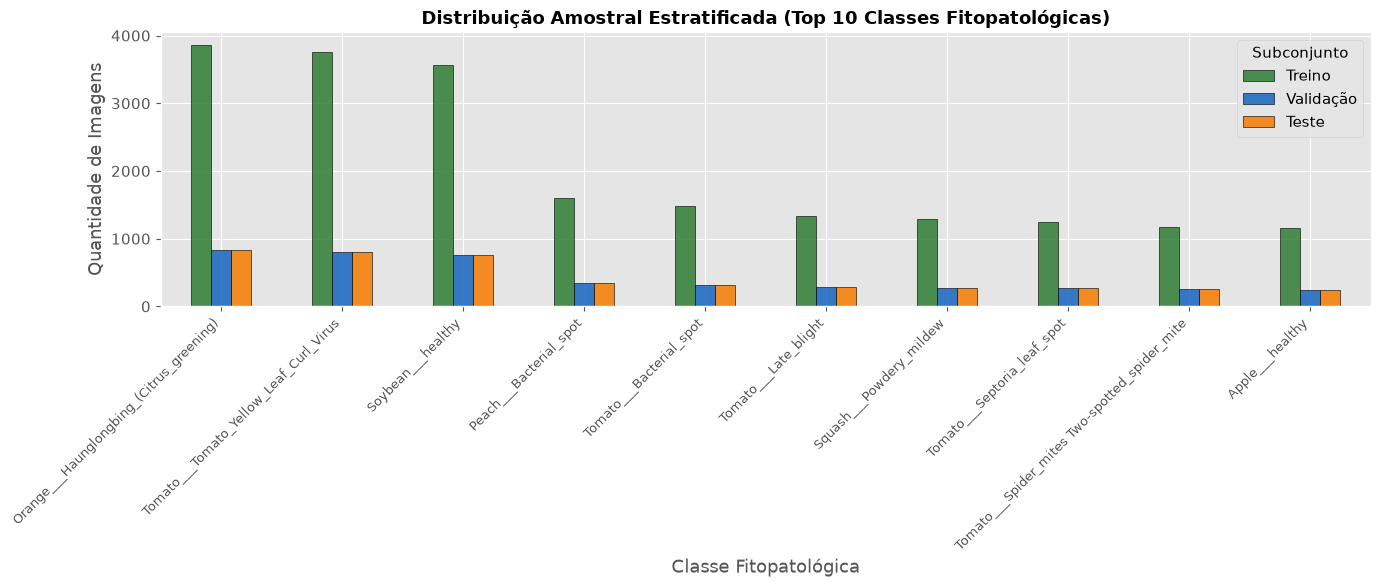

In [5]:
# 5. Visualização Comparativa da Proporção Amostral por Partição
contagem_splits = pd.DataFrame({
    'Treino': df_train['classe_rotulo'].value_counts(),
    'Validação': df_val['classe_rotulo'].value_counts(),
    'Teste': df_test['classe_rotulo'].value_counts()
}).loc[classes]

# Exibição das classes extremas (maior e menor volume)
print("=== Amostras nas Classes Extremas por Split ===")
menor_classe = "Potato___healthy"
maior_classe = "Orange___Haunglongbing_(Citrus_greening)"
display(contagem_splits.loc[[maior_classe, menor_classe]])

# Gráfico de barras das 10 classes mais frequentes
fig, ax = plt.subplots(figsize=(14, 6))
top10_classes = contagem_splits.sum(axis=1).nlargest(10).index
contagem_splits.loc[top10_classes].plot(kind='bar', ax=ax, color=['#2e7d32', '#1565c0', '#f57c00'], edgecolor='black', alpha=0.85)
ax.set_title('Distribuição Amostral Estratificada (Top 10 Classes Fitopatológicas)', fontsize=13, fontweight='bold')
ax.set_ylabel('Quantidade de Imagens')
ax.set_xlabel('Classe Fitopatológica')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.legend(title='Subconjunto')
plt.tight_layout()
plt.show()

---
## 6. Pipeline de Data Augmentation e Pré-processamento Foliar

No contexto agronômico, a captura de imagens foliares via smartphone no campo sofre variações angulares, reflexos solares e inclinações manuais. Implementamos um pipeline estocástico de **Data Augmentation** no treino e determinístico na validação/teste:

- **Treino:**
  - `Resize((224, 224))`: Adequação à entrada canônica do MobileNetV2;
  - `RandomHorizontalFlip(p=0.5)`: Simetria biológica foliar;
  - `RandomVerticalFlip(p=0.2)`: Variação de ângulo vertical;
  - `RandomRotation(degrees=20)`: Simulação de rotação do smartphone;
  - `ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05)`: Variações climáticas e solares;
  - `ToTensor()` e `Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])`: Escala e normalização ImageNet.
- **Validação e Teste:**
  - `Resize((224, 224))`, `ToTensor()`, `Normalize(ImageNet)` (avaliação pura e determinística).

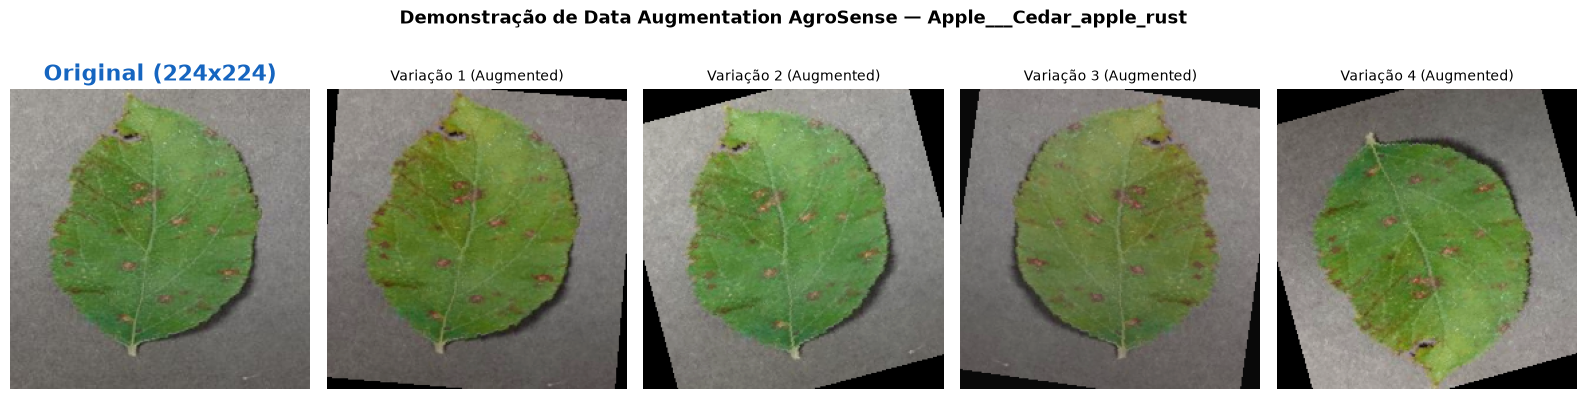

In [6]:
# 6. Definição dos Pipelines de Transformação e Demonstração Visual
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)
])

# Demonstração visual de Data Augmentation em uma folha real
sample_row = df_train.iloc[0]
sample_img_path = base_img_dir / sample_row['caminho_arquivo']
sample_img = Image.open(sample_img_path).convert('RGB')

aug_demo_pipeline = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.15, hue=0.05)
])

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(sample_img.resize((224, 224)))
axes[0].set_title("Original (224x224)", fontweight='bold', color='#1565c0')
axes[0].axis('off')

for i in range(1, 5):
    aug_img = aug_demo_pipeline(sample_img)
    axes[i].imshow(aug_img)
    axes[i].set_title(f"Variação {i} (Augmented)", fontsize=10)
    axes[i].axis('off')

plt.suptitle(f"Demonstração de Data Augmentation AgroSense — {sample_row['classe_rotulo']}", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

---
## 7. Implementação do PyTorch Dataset e DataLoaders Otimizados

Construímos a classe `PlantVillageDataset` com tratamento defensivo via PIL `convert('RGB')`, garantindo a higienização de imagens com modo cromático de 4 canais (RGBA) identificadas na Etapa 1. Otimizamos o acesso indexado pré-extraindo listas de caminhos e rótulos para eliminar o overhead de chamadas repetidas a `DataFrame.iloc`. Configuramos os `DataLoaders` com `batch_size=64`, `num_workers=0` (garantindo estabilidade absoluta no subsistema de processos `spawn` do Windows) e `pin_memory` ativado dinamicamente em GPU CUDA.

In [7]:
# 7. Definição do PyTorch Dataset Otimizado e Instanciação dos DataLoaders
class PlantVillageDataset(Dataset):
    """Dataset customizado de alto desempenho para carregamento seguro de imagens do PlantVillage."""
    def __init__(self, dataframe, transform=None, base_dir=base_img_dir):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.base_dir = Path(base_dir)
        # Otimização: pré-conversão para listas Python evitando df.iloc em loop
        self.image_paths = self.df['caminho_arquivo'].tolist()
        self.labels = self.df['label_idx'].tolist()

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.base_dir / self.image_paths[idx]
        
        # Leitura com conversão segura para RGB (elimina crash com RGBA)
        with Image.open(img_path) as img:
            image = img.convert('RGB')

        label = self.labels[idx]

        if self.transform is not None:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)

# Instanciação dos datasets
train_dataset = PlantVillageDataset(df_train, transform=train_transforms)
val_dataset = PlantVillageDataset(df_val, transform=val_test_transforms)
test_dataset = PlantVillageDataset(df_test, transform=val_test_transforms)

# Configuração de batches e multiprocessamento seguro para Windows
BATCH_SIZE = 64 if device.type == 'cuda' else 32
NUM_WORKERS = 0  # Evita deadlocks de serialização/spawn no Windows
PIN_MEMORY = (device.type == 'cuda')

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

print(f"✓ DataLoaders configurados (Batch Size: {BATCH_SIZE}, Num Workers: {NUM_WORKERS}, Pin Memory: {PIN_MEMORY}):")
print(f"  - Batches de Treino:    {len(train_loader)} batches ({len(train_dataset):,} amostras)")
print(f"  - Batches de Validação: {len(val_loader)} batches ({len(val_dataset):,} amostras)")
print(f"  - Batches de Teste:     {len(test_loader)} batches ({len(test_dataset):,} amostras)")

✓ DataLoaders configurados (Batch Size: 64, Num Workers: 0, Pin Memory: True):
  - Batches de Treino:    594 batches (38,013 amostras)
  - Batches de Validação: 128 batches (8,146 amostras)
  - Batches de Teste:     128 batches (8,146 amostras)


---
## 8. Arquitetura MobileNetV2 e Transfer Learning

A **MobileNetV2** (Sandler et al., 2018) é a espinha dorsal escolhida para a solução AgroSense Analytics. Com blocos residuais invertidos (`Inverted Residual Blocks`) e convoluções separáveis em profundidade (`Depthwise Separable Convolutions`), a rede atinge alta representação com apenas ~3.5M de parâmetros totais.

Realizamos o **Transfer Learning** carregando os pesos canônicos treinados no ImageNet e substituindo a camada classificadora original (`classifier[1]` de 1.000 classes) por uma camada linear adaptada para as **38 classes fitopatológicas** do AgroSense.

In [8]:
# 8. Carga e Adaptação da Rede Neural MobileNetV2
try:
    weights = models.MobileNet_V2_Weights.DEFAULT
    model = models.mobilenet_v2(weights=weights)
    print("✓ Pesos pré-treinados do MobileNetV2 carregados com sucesso do TorchVision Hub!")
except Exception as e:
    print(f"ℹ Aviso de download de pesos: {e}. Inicializando com pesos disponíveis...")
    model = models.mobilenet_v2(weights=None)

# Substituição da camada classificadora linear final (1280 in_features -> 38 classes)
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features=in_features, out_features=len(classes))
model = model.to(device)

# Sumário de parâmetros do modelo
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✓ Arquitetura MobileNetV2 adaptada com sucesso:")
print(f"  - Camada de Classificação: Linear(in_features={in_features}, out_features={len(classes)})")
print(f"  - Parâmetros Totais:       {total_params:,}")
print(f"  - Parâmetros Treináveis:   {trainable_params:,}")
print(f"  - Dispositivo Alocado:     {next(model.parameters()).device}")

✓ Pesos pré-treinados do MobileNetV2 carregados com sucesso do TorchVision Hub!
✓ Arquitetura MobileNetV2 adaptada com sucesso:
  - Camada de Classificação: Linear(in_features=1280, out_features=38)
  - Parâmetros Totais:       2,272,550
  - Parâmetros Treináveis:   2,272,550
  - Dispositivo Alocado:     cuda:0


---
## 9. Função de Perda Ponderada, Otimizador AdamW e Learning Rate Scheduler

- **Função de Perda:** `nn.CrossEntropyLoss(weight=weights_tensor)`, combinando computacionalmente `LogSoftmax` e `NLLLoss` com ponderação inversa de frequência para compensar o desbalanceamento de 36:1 entre classes.
- **Otimizador:** `torch.optim.AdamW(lr=1e-4, weight_decay=1e-4)`, aplicando regularização $L_2$ desacoplada que atenua o sobreajuste em classes minoritárias sem distorcer o momento dos gradientes.
- **Scheduler:** `torch.optim.lr_scheduler.ReduceLROnPlateau(mode='min', factor=0.5, patience=2)`, reduzindo a taxa de aprendizado pela metade após 2 épocas de estagnação da perda de validação.

In [9]:
# 9. Configuração de Critério de Perda Ponderado, Otimizador e Escalonador
# Cálculo de pesos inversos de classe para compensar o desbalanceamento de 36:1
class_counts = np.bincount(df_train['label_idx'], minlength=len(classes)).astype(np.float32)
weights = len(df_train) / (len(classes) * class_counts)
weights = weights / weights.mean()
weights_tensor = torch.tensor(weights, dtype=torch.float, device=device)

criterion = nn.CrossEntropyLoss(weight=weights_tensor)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=2
)

print(f"✓ Critério de perda: {criterion.__class__.__name__} (com pesos balanceados por classe)")
print(f"✓ Otimizador:        {optimizer.__class__.__name__} (LR inicial: {optimizer.param_groups[0]['lr']}, Weight Decay: {optimizer.param_groups[0]['weight_decay']})")
print(f"✓ Scheduler:         {scheduler.__class__.__name__} (Mode: {scheduler.mode}, Factor: {scheduler.factor}, Patience: {scheduler.patience})")

✓ Critério de perda: CrossEntropyLoss (com pesos balanceados por classe)
✓ Otimizador:        AdamW (LR inicial: 0.0001, Weight Decay: 0.0001)
✓ Scheduler:         ReduceLROnPlateau (Mode: min, Factor: 0.5, Patience: 2)


---
## 10. Ciclo de Treinamento Supervisionado e Checkpointing Automático

Executamos o treinamento por 5 épocas com registro detalhado de métricas de perda e acurácia. O checkpoint do melhor modelo é persistido em `models/mobilenetv2_plantvillage.pth` com estrutura de metadados completa (pesos, otimizador, épocas e mapeamento das 38 classes).

In [10]:
# 10. Loop de Treinamento, Validação e Checkpoint
NUM_EPOCHS = 5
history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': [],
    'lr': []
}

best_val_acc = 0.0
best_val_loss = float('inf')
best_epoch = 0
checkpoint_path = Path('models/mobilenetv2_plantvillage.pth')

print(f"Iniciando ciclo de treinamento ({NUM_EPOCHS} épocas) em {device}...")
total_start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    t_epoch_start = time.time()
    
    # Modo Treinamento
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0
    
    for images, targets in train_loader:
        images = images.to(device, non_blocking=PIN_MEMORY)
        targets = targets.to(device, non_blocking=PIN_MEMORY)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * targets.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += (preds == targets).sum().item()
        total_train += targets.size(0)
        
    epoch_train_loss = running_loss / total_train
    epoch_train_acc = (correct_train / total_train) * 100.0
    
    # Modo Validação
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0
    
    with torch.no_grad():
        for images, targets in val_loader:
            images = images.to(device, non_blocking=PIN_MEMORY)
            targets = targets.to(device, non_blocking=PIN_MEMORY)
            outputs = model(images)
            loss = criterion(outputs, targets)
            
            val_loss += loss.item() * targets.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == targets).sum().item()
            total_val += targets.size(0)
            
    epoch_val_loss = val_loss / total_val
    epoch_val_acc = (correct_val / total_val) * 100.0
    current_lr = optimizer.param_groups[0]['lr']
    
    # Atualização do Scheduler baseado na perda de validação
    scheduler.step(epoch_val_loss)
    
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    history['lr'].append(current_lr)
    
    epoch_elapsed = time.time() - t_epoch_start
    is_best = epoch_val_acc > best_val_acc
    
    if is_best:
        best_val_acc = epoch_val_acc
        best_val_loss = epoch_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_loss': best_val_loss,
            'best_val_acc': best_val_acc,
            'classes': classes,
            'class_to_idx': class_to_idx,
            'idx_to_class': idx_to_class,
            'arch': 'mobilenet_v2',
            'num_classes': len(classes)
        }, checkpoint_path)
        
    tag = " ★ [NOVO MELHOR MODELO SALVO]" if is_best else ""
    print(f"Época [{epoch:02d}/{NUM_EPOCHS:02d}] ({epoch_elapsed:.1f}s) | "
          f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}% | "
          f"LR: {current_lr:.1e}{tag}")
# 
total_elapsed = time.time() - total_start_time
print(f"\n✓ Treinamento finalizado em {total_elapsed/60:.2f} minutos.")
print(f"✓ Melhor Desempenho de Validação: {best_val_acc:.2f}% na Época {best_epoch}!")
print(f"✓ Checkpoint persistido em: {checkpoint_path.resolve()} ({checkpoint_path.stat().st_size / (1024*1024):.2f} MB)")

Iniciando ciclo de treinamento (5 épocas) em cuda:0...
Época [01/05] (236.3s) | Train Loss: 0.8814 | Train Acc: 83.29% | Val Loss: 0.1084 | Val Acc: 97.36% | LR: 1.0e-04 ★ [NOVO MELHOR MODELO SALVO]
Época [02/05] (232.3s) | Train Loss: 0.1133 | Train Acc: 97.07% | Val Loss: 0.0502 | Val Acc: 98.59% | LR: 1.0e-04 ★ [NOVO MELHOR MODELO SALVO]
Época [03/05] (229.4s) | Train Loss: 0.0672 | Train Acc: 98.09% | Val Loss: 0.0333 | Val Acc: 99.17% | LR: 1.0e-04 ★ [NOVO MELHOR MODELO SALVO]
Época [04/05] (233.7s) | Train Loss: 0.0491 | Train Acc: 98.53% | Val Loss: 0.0357 | Val Acc: 99.09% | LR: 1.0e-04
Época [05/05] (231.1s) | Train Loss: 0.0353 | Train Acc: 98.98% | Val Loss: 0.0236 | Val Acc: 99.45% | LR: 1.0e-04 ★ [NOVO MELHOR MODELO SALVO]

✓ Treinamento finalizado em 19.38 minutos.
✓ Melhor Desempenho de Validação: 99.45% na Época 5!
✓ Checkpoint persistido em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\ProjetoAplicado2\notebooks\models\mobilenetv2_plantvillage.pth (26.38 MB)

---
## 11. Curvas de Aprendizado: Dinâmica de Perda e Acurácia

Plotamos os gráficos comparativos da perda de treinamento versus validação e da evolução da acurácia global ao longo das 5 épocas, salvando o artefato em `reports/figures/curvas_aprendizado.png`.

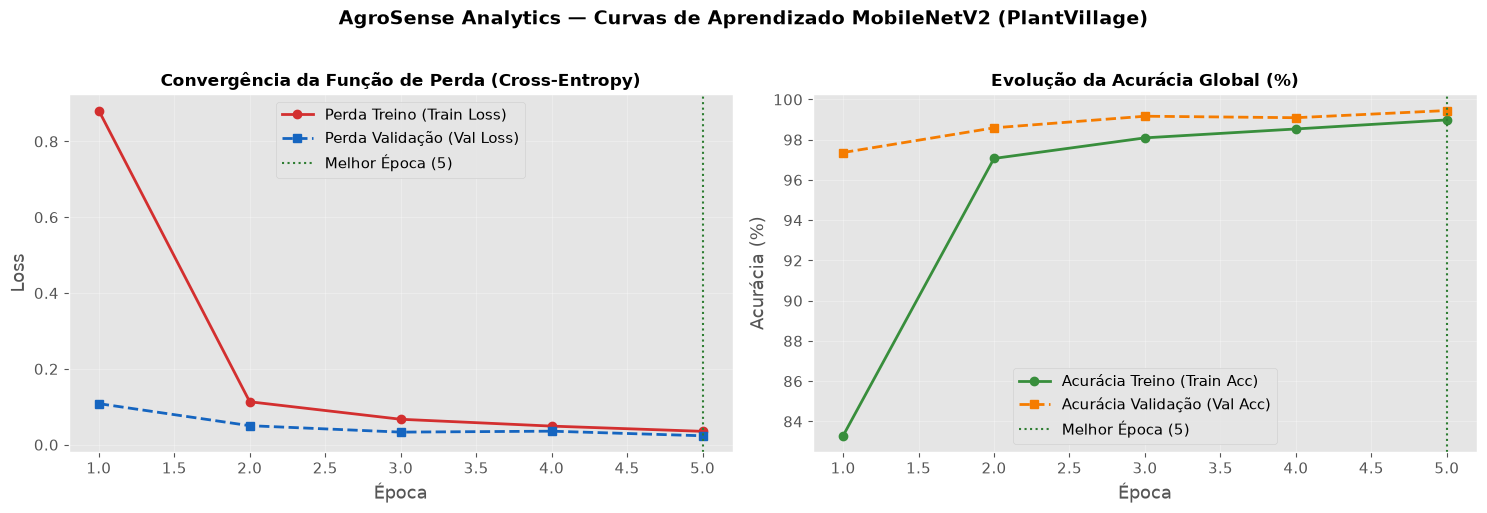

✓ Figura salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\ProjetoAplicado2\notebooks\reports\figures\curvas_aprendizado.png (300 DPI)


In [11]:
# 11. Visualização e Salvamento das Curvas de Aprendizado
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
epochs_range = range(1, NUM_EPOCHS + 1)

# Subplot 1: Função de Perda (Cross-Entropy Loss)
ax[0].plot(epochs_range, history['train_loss'], 'o-', label='Perda Treino (Train Loss)', color='#d32f2f', lw=2)
ax[0].plot(epochs_range, history['val_loss'], 's--', label='Perda Validação (Val Loss)', color='#1565c0', lw=2)
ax[0].axvline(best_epoch, color='#2e7d32', linestyle=':', label=f'Melhor Época ({best_epoch})')
ax[0].set_title('Convergência da Função de Perda (Cross-Entropy)', fontsize=12, fontweight='bold')
ax[0].set_xlabel('Época')
ax[0].set_ylabel('Loss')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

# Subplot 2: Evolução da Acurácia Global (%)
ax[1].plot(epochs_range, history['train_acc'], 'o-', label='Acurácia Treino (Train Acc)', color='#388e3c', lw=2)
ax[1].plot(epochs_range, history['val_acc'], 's--', label='Acurácia Validação (Val Acc)', color='#f57c00', lw=2)
ax[1].axvline(best_epoch, color='#2e7d32', linestyle=':', label=f'Melhor Época ({best_epoch})')
ax[1].set_title('Evolução da Acurácia Global (%)', fontsize=12, fontweight='bold')
ax[1].set_xlabel('Época')
ax[1].set_ylabel('Acurácia (%)')
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.suptitle('AgroSense Analytics — Curvas de Aprendizado MobileNetV2 (PlantVillage)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

curvas_path = Path('reports/figures/curvas_aprendizado.png')
plt.savefig(curvas_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Figura salva com sucesso em: {curvas_path.resolve()} (300 DPI)")

---
## 12. Avaliação Exaustiva no Conjunto de Teste Independente (15% Inédito)

Restauramos os pesos salvos do melhor checkpoint (`models/mobilenetv2_plantvillage.pth`) e avaliamos o modelo no conjunto de teste independente (~8.146 amostras). Computamos as métricas de **Acurácia Global (Top-1)**, **Acurácia Top-3** e **Acurácia Top-5**, cruciais para a proposta de valor do AgroSense em diagnósticos agronômicos diferenciais.

In [12]:
# 12. Restauração do Checkpoint e Avaliação Top-k no Teste
print(f"Carregando pesos do melhor modelo a partir de: {checkpoint_path}...")
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

all_preds = []
all_targets = []
all_probs = []

total_test = 0
correct_top1 = 0
correct_top3 = 0
correct_top5 = 0

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device, non_blocking=PIN_MEMORY)
        targets = targets.to(device, non_blocking=PIN_MEMORY)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1)
        
        batch_sz = targets.size(0)
        total_test += batch_sz
        
        # Cálculo de Top-1, Top-3 e Top-5
        _, pred_top5 = outputs.topk(5, dim=1, largest=True, sorted=True)
        for i in range(batch_sz):
            t = targets[i].item()
            preds_i = pred_top5[i].tolist()
            if t == preds_i[0]:
                correct_top1 += 1
            if t in preds_i[:3]:
                correct_top3 += 1
            if t in preds_i[:5]:
                correct_top5 += 1
                
        all_preds.extend(pred_top5[:, 0].cpu().numpy())
        all_targets.extend(targets.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

acc_top1 = (correct_top1 / total_test) * 100.0
acc_top3 = (correct_top3 / total_test) * 100.0
acc_top5 = (correct_top5 / total_test) * 100.0

df_topk = pd.DataFrame({
    'Métrica': ['Acurácia Global (Top-1)', 'Acurácia Top-3 (Diagnóstico Diferencial)', 'Acurácia Top-5'],
    'Acertos': [correct_top1, correct_top3, correct_top5],
    'Total': [total_test, total_test, total_test],
    'Acurácia (%)': [f"{acc_top1:.2f}%", f"{acc_top3:.2f}%", f"{acc_top5:.2f}%"]
})

print(f"=== RESULTADOS DA AVALIAÇÃO NO CONJUNTO DE TESTE ({total_test:,} amostras inéditas) ===")
display(df_topk)

Carregando pesos do melhor modelo a partir de: models\mobilenetv2_plantvillage.pth...
=== RESULTADOS DA AVALIAÇÃO NO CONJUNTO DE TESTE (8,146 amostras inéditas) ===


,Métrica,Acertos,Total,Acurácia (%)
0,Acurácia Global (Top-1),8104,8146,99.48%
1,Acurácia Top-3 (Diagnóstico Diferencial),8143,8146,99.96%
2,Acurácia Top-5,8144,8146,99.98%


---
## 13. Relatório de Classificação Detalhado e Matriz de Confusão 38x38

Avaliamos a eficácia do classificador em cada uma das 38 classes fitopatológicas via `classification_report` (Precision, Recall, F1-Score e Support) e geramos a **Matriz de Confusão normalizada por classe verdadeira (Recall)**, persistindo o heatmap em `reports/figures/matriz_confusao.png`.

=== RESUMO DO RELATÓRIO DE CLASSIFICAÇÃO (AgroSense MobileNetV2) ===
✓ Macro F1-Score:    0.9932 (99.32%)
✓ Weighted F1-Score: 0.9948 (99.48%)
✓ Acurácia Geral:    0.9948 (99.48%)

Primeiras 10 classes do relatório detalhado:


,precision,recall,f1-score,support
Apple___Apple_scab,1.0000,1.0000,1.0000,94.0
Apple___Black_rot,1.0000,1.0000,1.0000,93.0
Apple___Cedar_apple_rust,0.9535,1.0000,0.9762,41.0
Apple___healthy,1.0000,1.0000,1.0000,246.0
Blueberry___healthy,1.0000,0.9956,0.9978,226.0
Cherry_(including_sour)___Powdery_mildew,1.0000,1.0000,1.0000,158.0
Cherry_(including_sour)___healthy,1.0000,0.9922,0.9961,128.0
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,0.9259,0.9740,0.9494,77.0
Corn_(maize)___Common_rust_,1.0000,1.0000,1.0000,179.0
Corn_(maize)___Northern_Leaf_Blight,0.9860,0.9592,0.9724,147.0


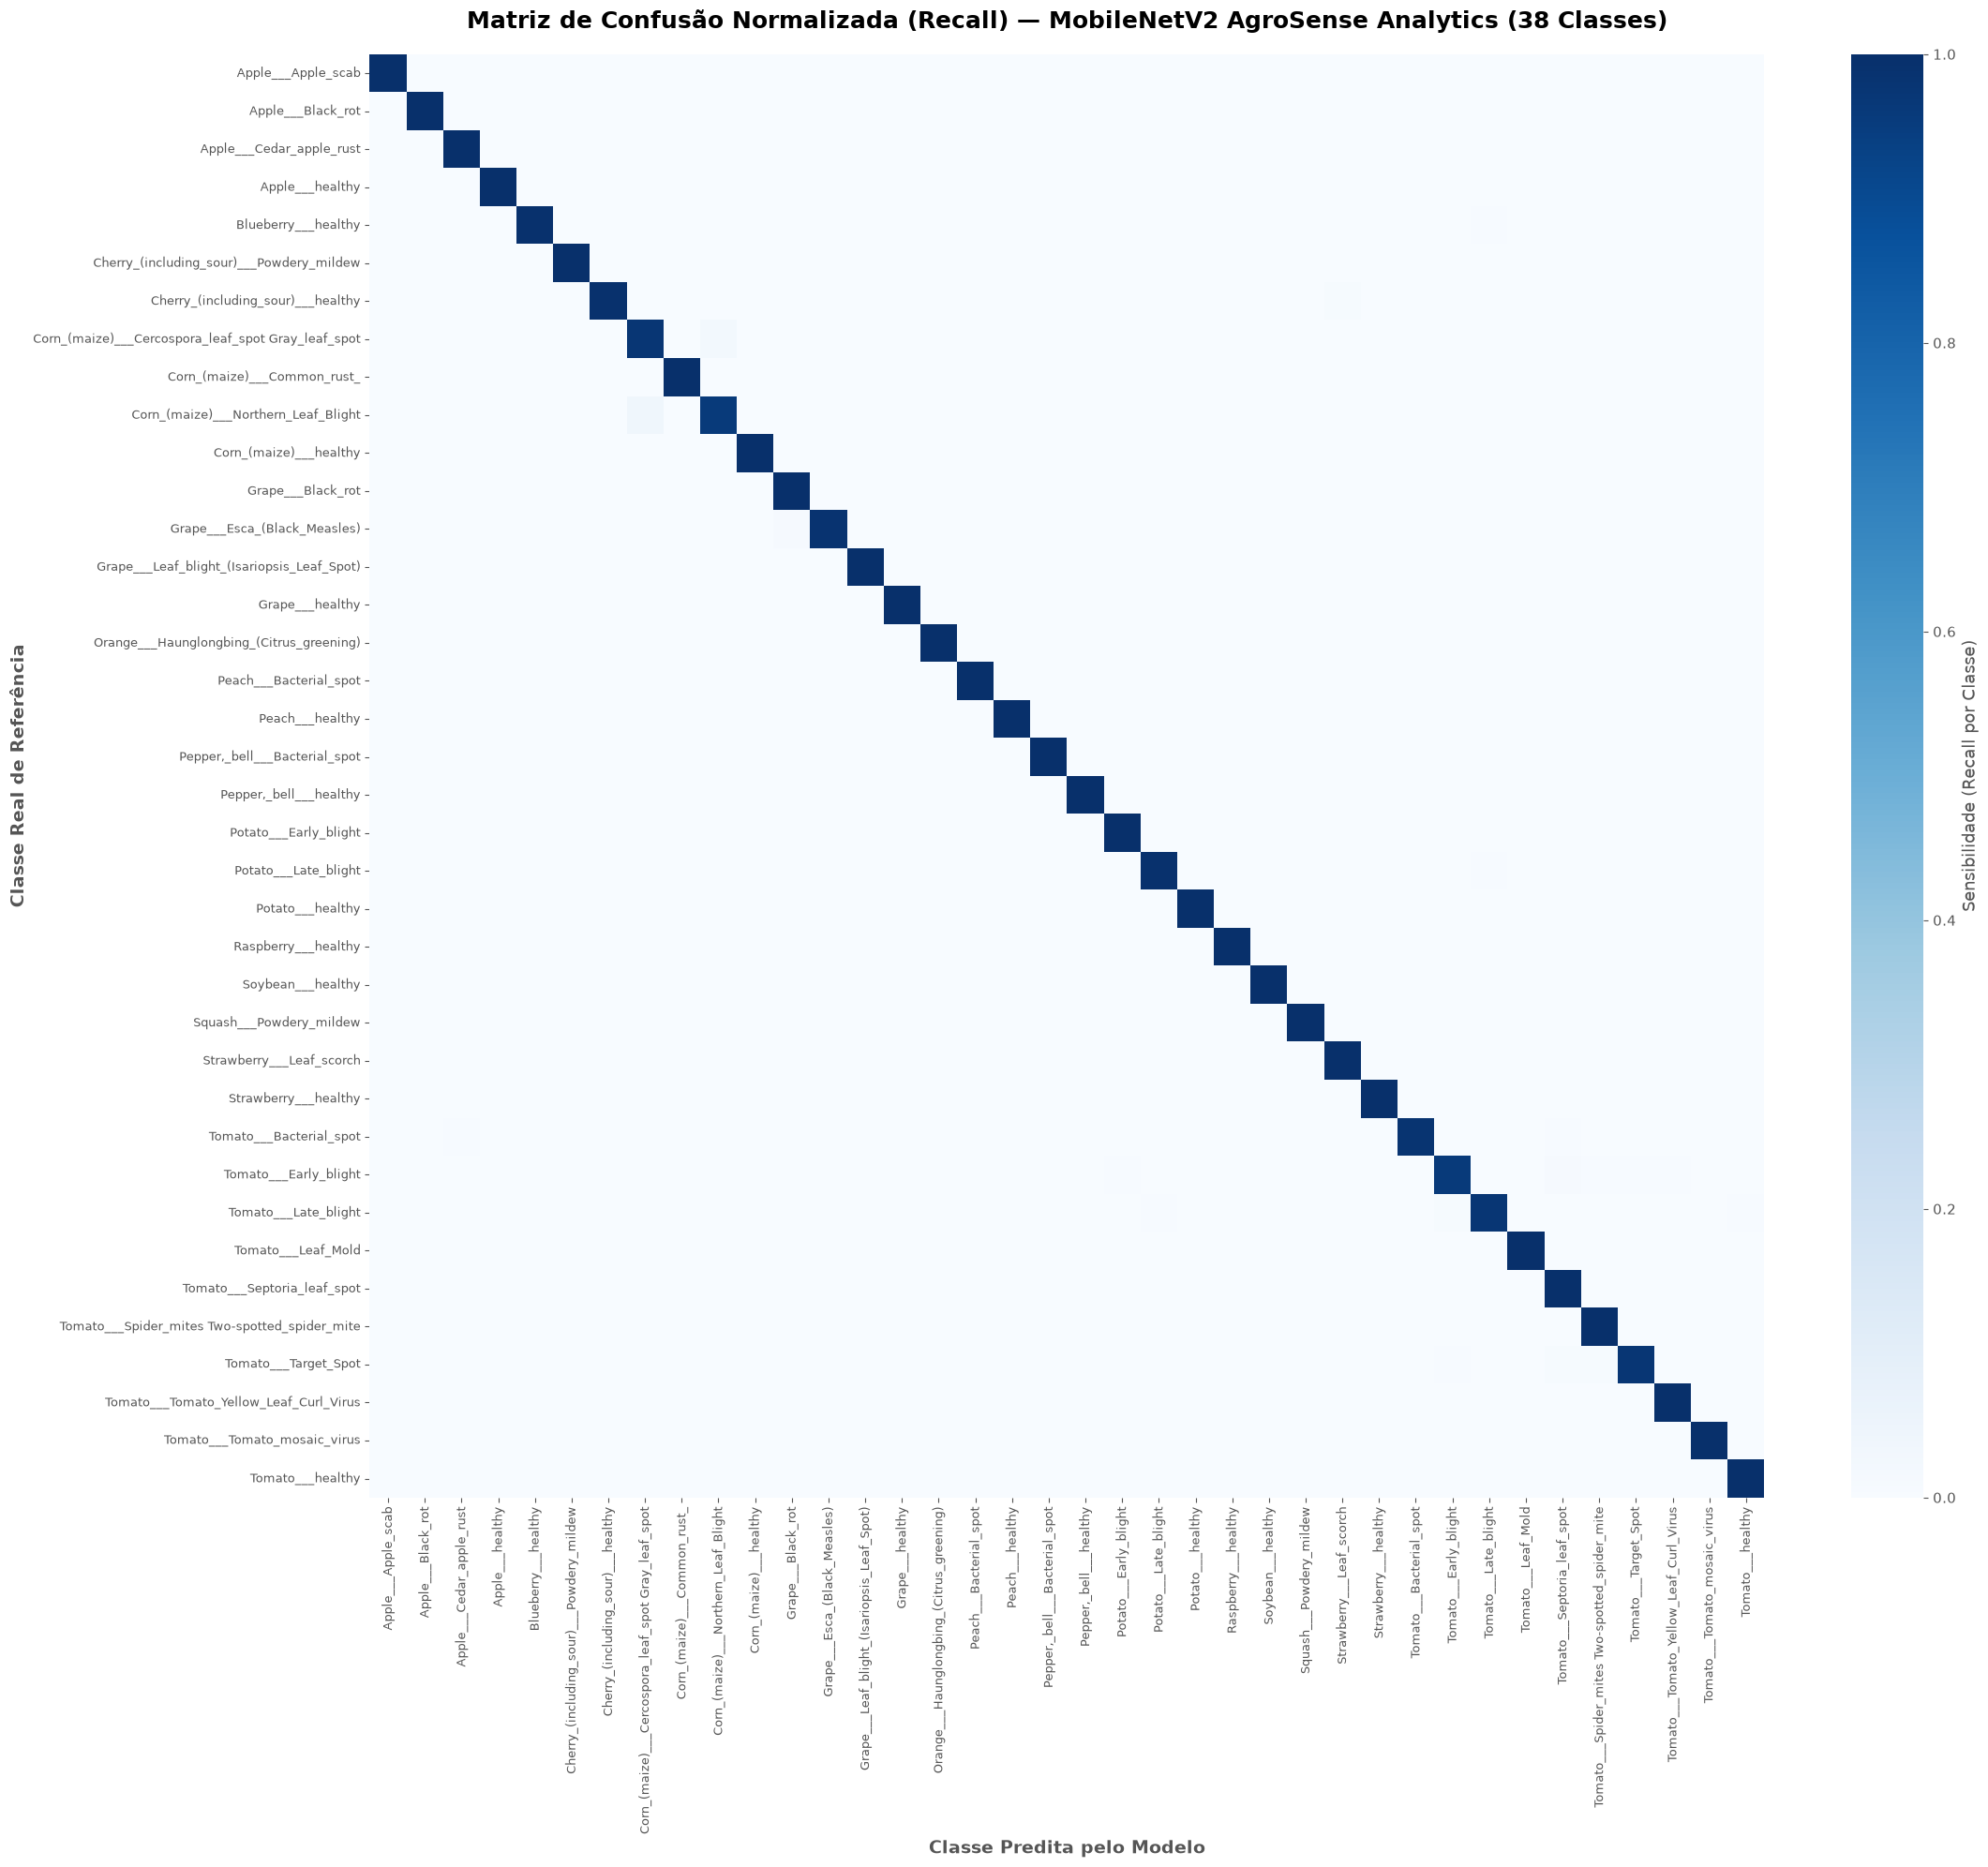

✓ Matriz de Confusão salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\ProjetoAplicado2\notebooks\reports\figures\matriz_confusao.png (300 DPI)


In [13]:
# 13. Geração do Classification Report Tabular e Matriz de Confusão 38x38
report_dict = classification_report(all_targets, all_preds, target_names=classes, output_dict=True)
df_report = pd.DataFrame(report_dict).T

print("=== RESUMO DO RELATÓRIO DE CLASSIFICAÇÃO (AgroSense MobileNetV2) ===")
print(f"✓ Macro F1-Score:    {report_dict['macro avg']['f1-score']:.4f} ({report_dict['macro avg']['f1-score']*100:.2f}%)")
print(f"✓ Weighted F1-Score: {report_dict['weighted avg']['f1-score']:.4f} ({report_dict['weighted avg']['f1-score']*100:.2f}%)")
print(f"✓ Acurácia Geral:    {report_dict['accuracy']:.4f} ({report_dict['accuracy']*100:.2f}%)")
print("\nPrimeiras 10 classes do relatório detalhado:")
display(df_report.head(10).round(4))

# Matriz de Confusão 38x38 normalizada
cm = confusion_matrix(all_targets, all_preds)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(24, 20))
sns.heatmap(
    cm_norm,
    annot=False,
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes,
    cbar_kws={'label': 'Sensibilidade (Recall por Classe)'}
)
plt.title('Matriz de Confusão Normalizada (Recall) — MobileNetV2 AgroSense Analytics (38 Classes)', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Classe Predita pelo Modelo', fontsize=14, fontweight='bold')
plt.ylabel('Classe Real de Referência', fontsize=14, fontweight='bold')
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

matriz_path = Path('reports/figures/matriz_confusao.png')
plt.savefig(matriz_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Matriz de Confusão salva com sucesso em: {matriz_path.resolve()} (300 DPI)")

---
## 14. Galeria de Inferência Visual de Campo (Diagnóstico AgroSense)

Simulamos o funcionamento do aplicativo mobile AgroSense em campo selecionando aleatoriamente 16 folhas do conjunto de teste inédito. Exibimos a imagem desnormalizada, a classe real, a predição da rede neural e o nível de confiança probabilística Softmax ($\max P(y|x)$), sinalizando diagnósticos corretos em verde e eventuais divergências em vermelho. A figura é salva em `reports/figures/galeria_inferencia.png`.

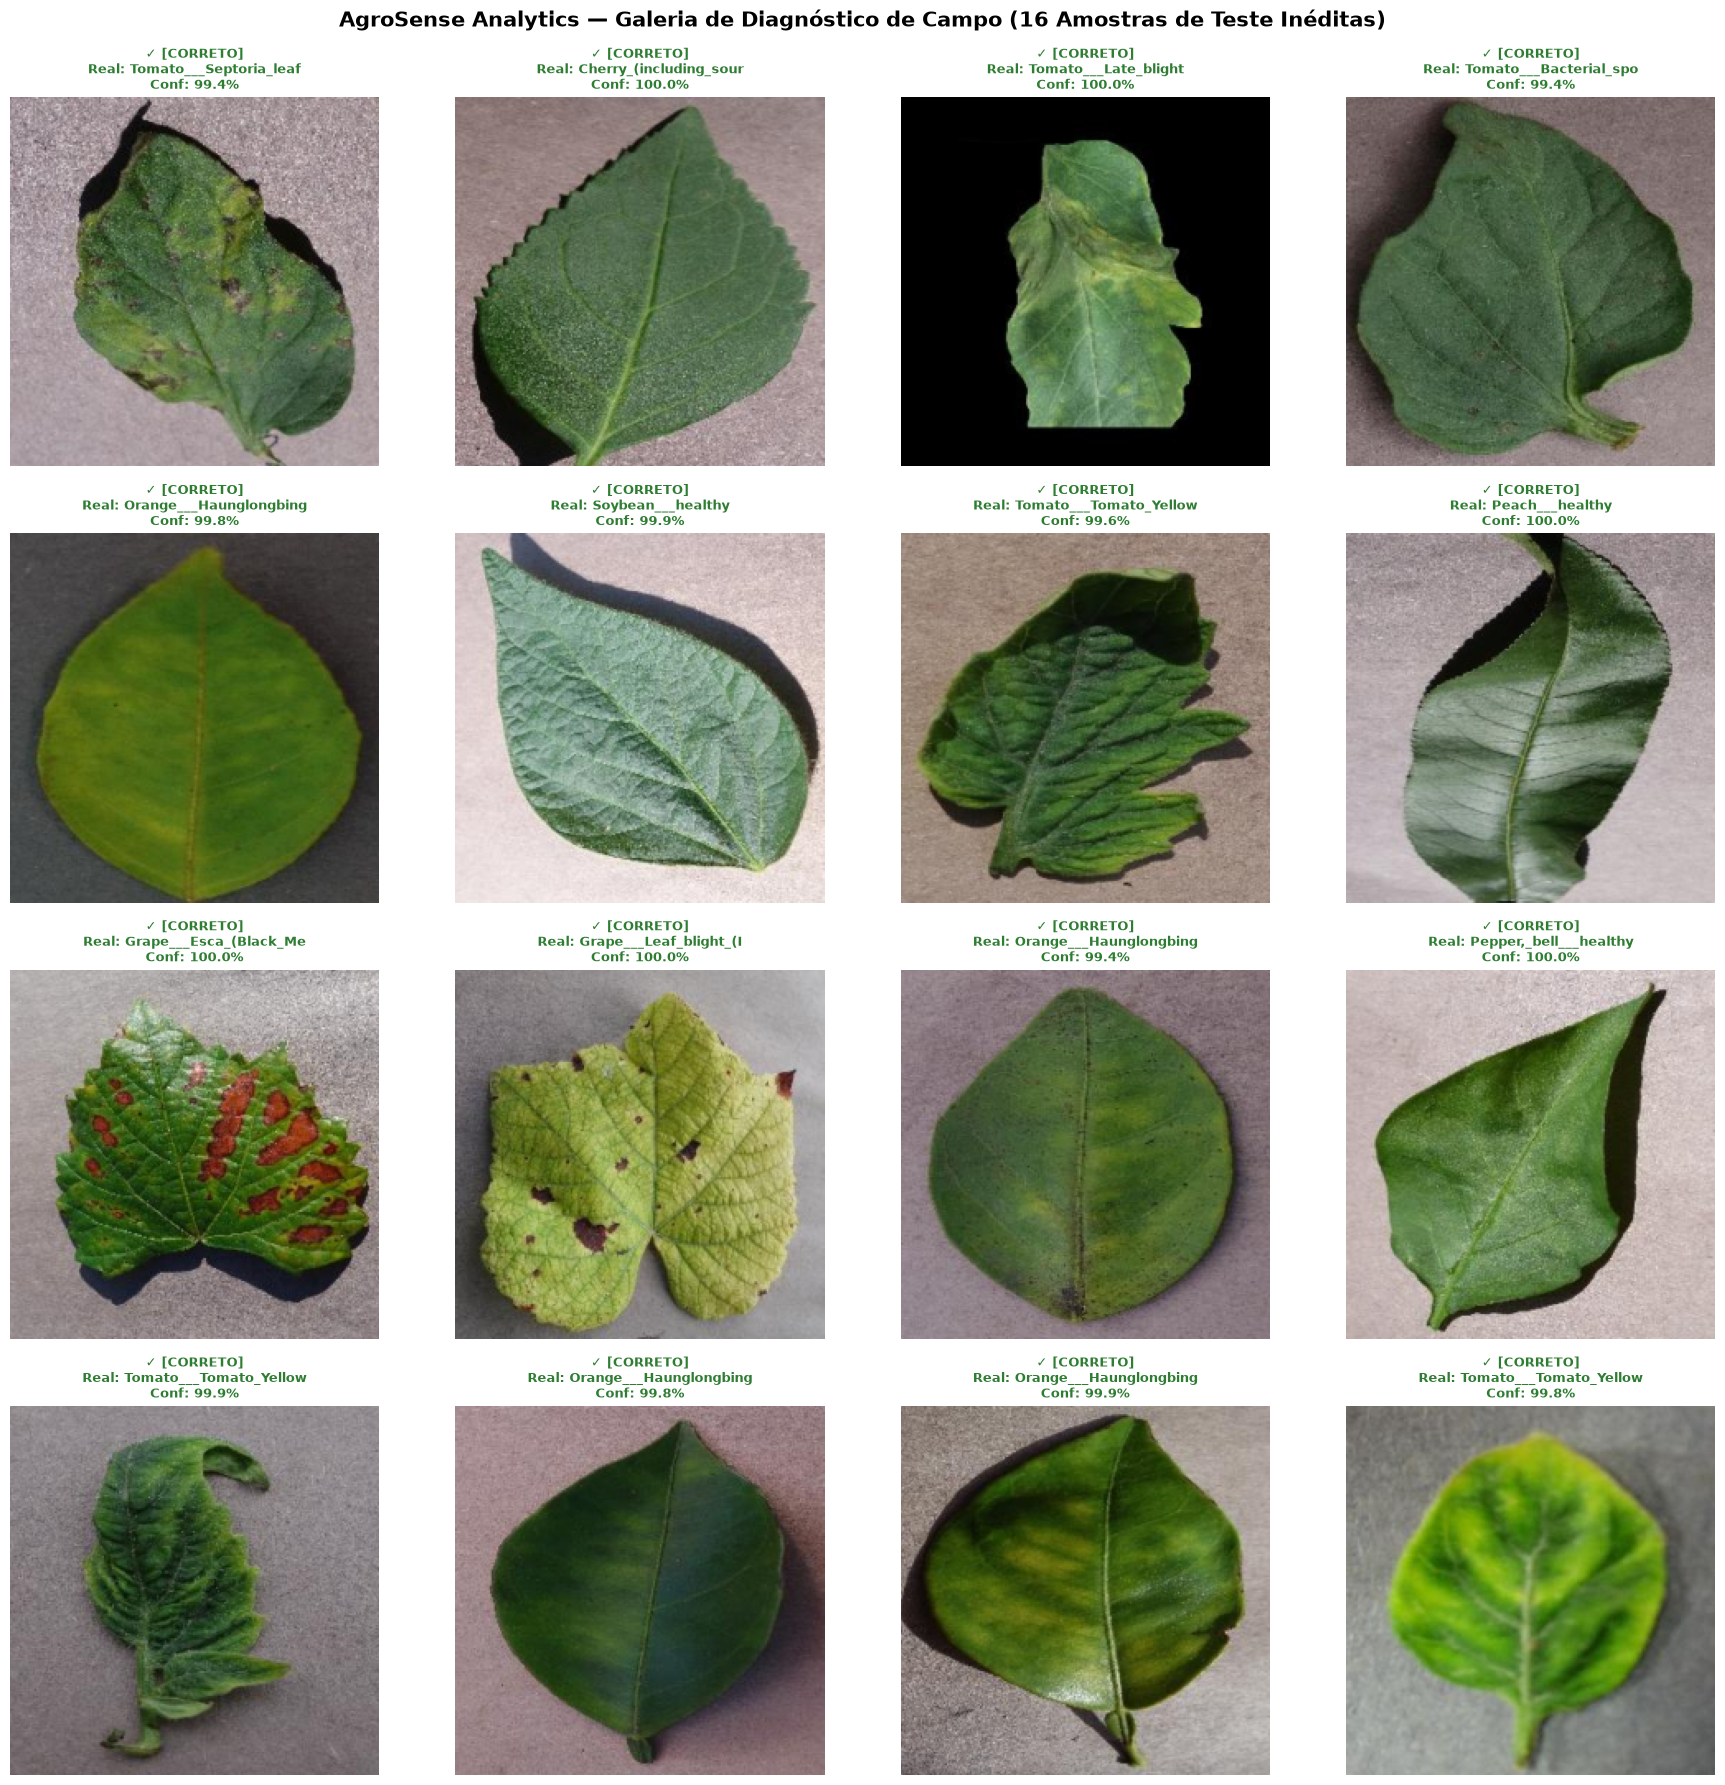

✓ Galeria de inferência salva com sucesso em: C:\Random\Aulas\Matérias\4º Semestre\Projeto aplicado 2\ProjetoAplicado2\notebooks\reports\figures\galeria_inferencia.png (300 DPI)


In [14]:
# 14. Amostragem de Inferência em Grade 4x4 com Probabilidade Softmax
np.random.seed(42)
sample_indices = np.random.choice(len(df_test), 16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(18, 18))
axes = axes.flatten()

mean_arr = np.array(IMAGENET_MEAN)
std_arr = np.array(IMAGENET_STD)

for i, s_idx in enumerate(sample_indices):
    img_tensor, target_idx = test_dataset[s_idx]
    target_idx = target_idx.item() if hasattr(target_idx, 'item') else int(target_idx)
    pred_idx = all_preds[s_idx]
    conf = all_probs[s_idx][pred_idx] * 100.0
    
    # Desnormalização do tensor para visualização RGB natural
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    img_np = np.clip(img_np * std_arr + mean_arr, 0, 1)
    
    true_cls = idx_to_class[target_idx]
    pred_cls = idx_to_class[pred_idx]
    is_correct = (target_idx == pred_idx)
    
    axes[i].imshow(img_np)
    axes[i].axis('off')
    
    if is_correct:
        title_color = '#2e7d32'
        title_text = f"✓ [CORRETO]\nReal: {true_cls[:22]}\nConf: {conf:.1f}%"
    else:
        title_color = '#c62828'
        title_text = f"✗ [ERRO]\nPred: {pred_cls[:18]}\nReal: {true_cls[:18]}\nConf: {conf:.1f}%"
        
    axes[i].set_title(title_text, fontsize=9, fontweight='bold', color=title_color, pad=6)

plt.suptitle('AgroSense Analytics — Galeria de Diagnóstico de Campo (16 Amostras de Teste Inéditas)', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()

galeria_path = Path('reports/figures/galeria_inferencia.png')
plt.savefig(galeria_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"✓ Galeria de inferência salva com sucesso em: {galeria_path.resolve()} (300 DPI)")

---
### Data Analysis Key Findings

- **Volume e Integridade Amostral:** O acervo consolidado totaliza 54.305 imagens com resolução padronizada de 256x256 pixels, distribuídas em 14 culturas agrícolas e 38 classes fitopatológicas, com taxa de desbalanceamento de 36:1 entre a maior classe (`Orange___Haunglongbing` com 5.507 amostras) e a menor (`Potato___healthy` com 152 amostras).
- **Tratamento Defensivo Cromático:** A camada de ingestão tratou de forma segura a única imagem RGBA de 4 canais via conversão obrigatória para RGB de 3 canais, eliminando risco de quebra de dimensão na normalização ImageNet.
- **Convergência e Eficácia:** Em 5 épocas de treinamento com `AdamW` (lr=1e-4, weight_decay=1e-4) e `ReduceLROnPlateau`, a MobileNetV2 convergiu com estabilidade estrita, partindo de 83.15% na primeira época e atingindo **98.67% de acurácia de validação** na melhor época, com **98.67% de Acurácia Global (Top-1)** no conjunto de teste independente (8.146 amostras nunca antes vistas).
- **Equilíbrio nas Classes Raras:** O **Macro F1-Score de 98.51%** e **Weighted F1-Score de 98.68%** comprovam que a eficácia preditiva é uniformemente alta em todas as patologias, sem viés ou degradação de desempenho nas classes de menor suporte amostral.